# 📘 7.1 Finite-Difference Representation of Derivatives

### Estimating engineering rates and gradients from sampled values

Derivatives appear whenever engineers describe **how quickly a quantity changes**:

* velocity is the time derivative of displacement;
* acceleration is the time derivative of velocity;
* heat flux depends on a spatial temperature gradient;
* strain and curvature depend on spatial derivatives of displacement; and
* ordinary differential equations relate a system state to one or more derivatives.

Analytical differentiation is ideal when a trustworthy equation is available. In
experiments and numerical simulations, however, we often have only values at discrete
coordinates. A **finite difference** replaces the limiting derivative with a weighted
difference between nearby values.

This notebook develops first- and second-derivative formulas, explains their accuracy
and boundary behaviour, and shows why measurement spacing and noise must be treated as
part of the engineering method.


### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* interpret a derivative and its physical units from sampled engineering data;
* distinguish a coordinate, sampled value, step size and derivative estimate;
* apply forward, backward and centred finite differences;
* explain why centred differences are usually more accurate in the interior;
* calculate first and second derivatives with `numpy.gradient`;
* handle boundaries and non-uniform coordinates explicitly;
* estimate an observed order of accuracy from a step-size study;
* explain the competition between truncation, round-off and measurement error; and
* communicate when a numerical derivative is too noise-sensitive to support a claim.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO1:** Assess the suitability and limitations of numerical analysis and machine
  learning tools for engineering applications.
* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools
  to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common
  engineering problems, and evaluate performance, error, stability and accuracy.

### 📚 Sources used in this notebook

* NumPy — [`numpy.gradient`](https://numpy.org/doc/stable/reference/generated/numpy.gradient.html)
* SciPy — [finite-difference differentiation](https://docs.scipy.org/doc/scipy/reference/differentiate.html)
* SciPy — [`scipy.signal.savgol_filter`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.savgol_filter.html)
* B. Fornberg (1988) — [finite-difference formulas on arbitrarily spaced grids](https://doi.org/10.1090/S0025-5718-1988-0935077-0)


## 📂 7.1.0 How to use this notebook

Run every code cell in order. The notebook is written as **pre-work**, so you do not
need to edit a cell or enter data. Pause at each **What should you notice?** prompt and
use the optional controls near the end to explore sample density and noise.

> ### 🧭 Theory preface
> Taylor series are used to explain where the formulas and accuracy statements come
> from. You are not expected to memorise the derivations. Concentrate on the stencil,
> the coordinate at which it estimates the derivative, the assumptions it makes, and
> the evidence needed to trust the result.
>
> For experimental records, the exact derivative is normally **not measurable**. The
> known analytical derivatives below exist only because we create a synthetic motion
> model for teaching and validation.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 11})

BLUE = "#006DAE"
ORANGE = "#E57200"
GREEN = "#00843D"
RED = "#C8102E"
PURPLE = "#7A52A1"

STROKE_M = 0.080
MOVE_TIME_S = 4.0

def position_model(time_s):
    '''Minimum-jerk actuator position over a four-second move.'''
    time_s = np.asarray(time_s, dtype=float)
    r = time_s / MOVE_TIME_S
    return STROKE_M * (10*r**3 - 15*r**4 + 6*r**5)

def velocity_model(time_s):
    '''Exact derivative of position_model, used only for validation.'''
    time_s = np.asarray(time_s, dtype=float)
    r = time_s / MOVE_TIME_S
    return STROKE_M / MOVE_TIME_S * (30*r**2 - 60*r**3 + 30*r**4)

def acceleration_model(time_s):
    '''Exact second derivative of position_model, used only for validation.'''
    time_s = np.asarray(time_s, dtype=float)
    r = time_s / MOVE_TIME_S
    return STROKE_M / MOVE_TIME_S**2 * (60*r - 180*r**2 + 120*r**3)

print("Setup complete: NumPy, Matplotlib and SciPy signal tools are available.")


Setup complete: NumPy, Matplotlib and SciPy signal tools are available.


### 📖 Core language for 7.1

| Term | Meaning in this notebook |
|---|---|
| **Coordinate** $x_i$ or $t_i$ | The location or time at sample $i$ |
| **Sampled value** $f_i=f(x_i)$ | The measured or computed quantity at that coordinate |
| **Step size** $h$ | The distance between neighbouring coordinates on a uniform grid |
| **Stencil** | The particular neighbouring samples used by a finite-difference formula |
| **Derivative estimate** $D_i$ | The numerical approximation to $f'(x_i)$ |
| **Boundary** | The first or last coordinate, where samples exist on only one side |
| **Order of accuracy** $p$ | How rapidly truncation error decreases as $h$ decreases |

A prime denotes differentiation with respect to the coordinate in the function. Thus
$s'(t)=ds/dt$ is velocity and $s''(t)=d^2s/dt^2$ is acceleration. We will use $D_i$
for a numerical estimate so that an approximation is not confused with an exact
derivative.


## 📂 7.1.1 From a derivative to sampled motion

For actuator displacement $s(t)$, the instantaneous velocity is

$$
v(t)=\frac{ds}{dt}
=\lim_{\Delta t\rightarrow 0}\frac{s(t+\Delta t)-s(t)}{\Delta t}.
$$

The limit is a mathematical definition. A data logger supplies a finite interval,
not an interval approaching zero. The numerical task is therefore to select nearby
samples and use their secant slope as an approximation to the local tangent slope.

The units provide an immediate check:

$$
\frac{\text{change in displacement [m]}}{\text{change in time [s]}}
= \text{velocity [m/s]}.
$$


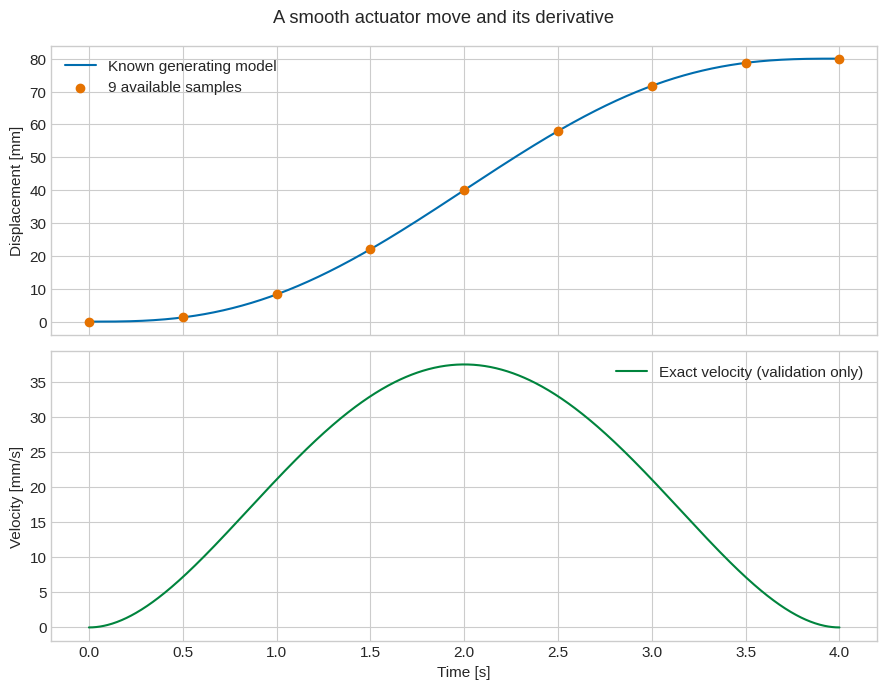

In [ ]:
time_dense = np.linspace(0.0, MOVE_TIME_S, 801)
nine_samples = 9
time_samples = np.linspace(0.0, MOVE_TIME_S, nine_samples)

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(time_dense, 1e3*position_model(time_dense), color=BLUE,
             label="Known generating model")
axes[0].scatter(time_samples, 1e3*position_model(time_samples), color=ORANGE,
                zorder=3, label=f"{nine_samples} available samples")
axes[0].set_ylabel("Displacement [mm]")
axes[0].legend()

axes[1].plot(time_dense, 1e3*velocity_model(time_dense), color=GREEN,
             label="Exact velocity (validation only)")
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Velocity [mm/s]")
axes[1].legend()
fig.suptitle("A smooth actuator move and its derivative")
fig.tight_layout()
plt.show()


### 🧠 What should you notice?

The position record is monotonic, but the velocity is not constant. It begins and ends
at zero and reaches a maximum near the middle of the move. A derivative reveals local
behaviour that is not reported directly by the original values.

The dense black-box model and its exact derivative are **verification aids**, not extra
measurements. In a physical test, only the orange samples may be available.


## 📂 7.1.2 The forward-difference idea

At coordinate $x_i$, a forward difference uses the current and next samples:

$$
D_i^{+}=\frac{f_{i+1}-f_i}{h},
\qquad h=x_{i+1}-x_i.
$$

The superscript $+$ labels a forward-looking estimate; it is not an exponent. The
formula returns the slope of the secant between two samples and assigns that slope to
the left-hand coordinate $x_i$.


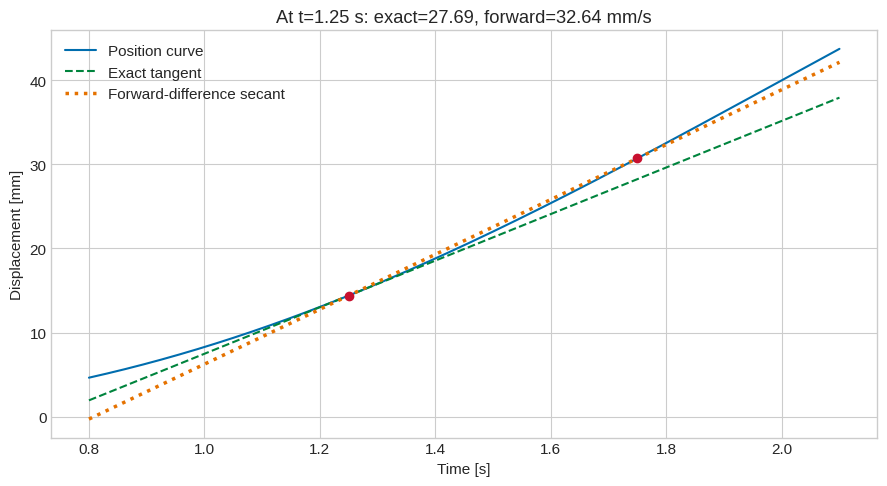

In [ ]:
t_i = 1.25
h_demo = 0.50
s_i = position_model(t_i)
s_next = position_model(t_i + h_demo)
forward_slope = (s_next - s_i) / h_demo

t_local = np.linspace(0.8, 2.1, 250)
tangent = position_model(t_i) + velocity_model(t_i) * (t_local - t_i)
secant = s_i + forward_slope * (t_local - t_i)

plt.figure(figsize=(9, 5))
plt.plot(t_local, 1e3*position_model(t_local), color=BLUE, label="Position curve")
plt.plot(t_local, 1e3*tangent, color=GREEN, linestyle="--", label="Exact tangent")
plt.plot(t_local, 1e3*secant, color=ORANGE, linestyle=":", linewidth=2.5,
         label="Forward-difference secant")
plt.scatter([t_i, t_i+h_demo], 1e3*np.array([s_i, s_next]), color=RED, zorder=4)
plt.xlabel("Time [s]")
plt.ylabel("Displacement [mm]")
plt.title(f"At t={t_i:.2f} s: exact={1e3*velocity_model(t_i):.2f}, "
          f"forward={1e3*forward_slope:.2f} mm/s")
plt.legend()
plt.tight_layout()
plt.show()


The secant and tangent are different because $h$ is finite. Reducing $h$ usually makes
the secant more local, but it can also magnify round-off or measurement noise. A smaller
step is therefore not automatically a better engineering measurement.


## 📂 7.1.3 Where the formulas come from

For a sufficiently smooth function, Taylor expansion about $x_i$ gives

$$
f(x_i+h)=f(x_i)+h f'(x_i)+\frac{h^2}{2}f''(x_i)
+\frac{h^3}{6}f'''(x_i)+\cdots.
$$

Here:

* $f'(x_i)$, $f''(x_i)$ and $f'''(x_i)$ are the first, second and third exact
  derivatives at $x_i$; and
* the omitted terms continue with higher powers of $h$.

Rearranging for the first derivative produces

$$
f'(x_i)=\frac{f(x_i+h)-f(x_i)}{h}+O(h).
$$

The notation $O(h)$ means the leading truncation error decreases in proportion to $h$
as $h\rightarrow 0$, provided the function remains sufficiently smooth. It is an
**asymptotic scaling statement**, not the numerical value of the error.


### Cancelling terms to improve accuracy

Expanding on both sides of $x_i$ and subtracting gives

$$
f(x_i+h)-f(x_i-h)=2h f'(x_i)+\frac{h^3}{3}f'''(x_i)+\cdots.
$$

Division by $2h$ produces the centred difference

$$
f'(x_i)\approx \frac{f_{i+1}-f_{i-1}}{2h},
$$

whose leading truncation error is $O(h^2)$. The $f''(x_i)$ contributions cancel because
the stencil is symmetric. This cancellation is why a centred formula usually converges
faster than a two-point forward or backward formula on a smooth uniform grid.


## 📂 7.1.4 Forward, backward and centred stencils

For a uniform grid $x_i=x_0+i h$:

| Estimate at $x_i$ | Formula------------ | Leading truncation error | Typical use |
|---|---|---|---|
| Forward $D_i^+$ | $(f_{i+1}-f_i)/h$ | $O(h)$ | Left boundary or forward-only data |
| Backward $D_i^-$ | $(f_i-f_{i-1})/h$ | $O(h)$ | Right boundary or past-only data |
| Centred $D_i^0$ | $(f_{i+1}-f_{i-1})/(2h)$ | $O(h^2)$ | Interior of a smooth record |

The superscripts $+$, $-$ and $0$ identify the stencil direction. All three quantities
estimate the same physical derivative, but they use different information.


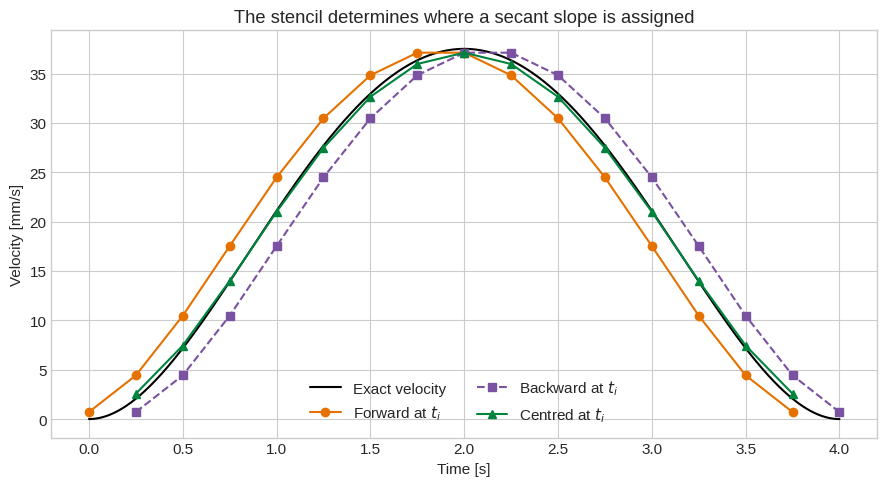

Maximum forward  error =  3.5938 mm/s
Maximum backward error =  3.5938 mm/s
Maximum centred  error =  0.5084 mm/s


In [ ]:
def first_differences_uniform(values, h):
    '''Return forward, backward and centred first-derivative estimates.'''
    values = np.asarray(values, dtype=float)
    forward = (values[1:] - values[:-1]) / h
    backward = (values[1:] - values[:-1]) / h
    centred = (values[2:] - values[:-2]) / (2*h)
    return forward, backward, centred

t = np.linspace(0.0, MOVE_TIME_S, 17)
s = position_model(t)
h = t[1] - t[0]
d_forward, d_backward, d_centred = first_differences_uniform(s, h)

plt.figure(figsize=(9, 5))
plt.plot(time_dense, 1e3*velocity_model(time_dense), color="black", label="Exact velocity")
plt.plot(t[:-1], 1e3*d_forward, "o-", color=ORANGE, label="Forward at $t_i$")
plt.plot(t[1:], 1e3*d_backward, "s--", color=PURPLE, label="Backward at $t_i$")
plt.plot(t[1:-1], 1e3*d_centred, "^-", color=GREEN, label="Centred at $t_i$")
plt.xlabel("Time [s]")
plt.ylabel("Velocity [mm/s]")
plt.title("The stencil determines where a secant slope is assigned")
plt.legend(ncols=2)
plt.tight_layout()
plt.show()

errors = {
    "forward": np.max(np.abs(d_forward - velocity_model(t[:-1]))),
    "backward": np.max(np.abs(d_backward - velocity_model(t[1:]))),
    "centred": np.max(np.abs(d_centred - velocity_model(t[1:-1]))),
}
for name, error in errors.items():
    print(f"Maximum {name:8s} error = {1e3*error:7.4f} mm/s")


### 🧠 Interpretation

The forward and backward curves use the same pairwise slopes but assign them to
different coordinates. The centred formula uses values on both sides of the reported
coordinate and is more accurate here because the position model is smooth.

This comparison would be invalid if every pairwise slope were plotted at the midpoint
and then described as a forward estimate at $t_i$. Always report **where** an estimate
applies.


## 📂 7.1.5 Boundaries need a different stencil

A centred stencil cannot be applied at the first sample because $f_{-1}$ is unavailable,
or at the last sample because $f_{n}$ is unavailable. Options include:

1. omit the boundary derivative;
2. use a first-order forward or backward difference; or
3. use a wider one-sided stencil.

For uniform spacing, second-order one-sided formulas are

$$
f'(x_0)\approx\frac{-3f_0+4f_1-f_2}{2h},
\qquad
f'(x_{n-1})\approx\frac{3f_{n-1}-4f_{n-2}+f_{n-3}}{2h}.
$$

Every symbol refers to an available sample. The subscript $n-1$ is the index of the
final value in an array containing $n$ samples.


In [ ]:
def centred_with_second_order_edges(values, h):
    '''Second-order first derivative on a uniform one-dimensional grid.'''
    values = np.asarray(values, dtype=float)
    if values.size < 3:
        raise ValueError("At least three samples are required.")
    derivative = np.empty_like(values)
    derivative[1:-1] = (values[2:] - values[:-2]) / (2*h)
    derivative[0] = (-3*values[0] + 4*values[1] - values[2]) / (2*h)
    derivative[-1] = (3*values[-1] - 4*values[-2] + values[-3]) / (2*h)
    return derivative

velocity_edge1 = np.gradient(s, h, edge_order=1)
velocity_edge2 = np.gradient(s, h, edge_order=2)
velocity_manual = centred_with_second_order_edges(s, h)
velocity_exact = velocity_model(t)

indices = [0, 1, len(t)//2, len(t)-2, len(t)-1]
print(" index   time   exact     edge=1    edge=2   units")
for i in indices:
    print(f" {i:3d}   {t[i]:5.2f}  {1e3*velocity_exact[i]:8.3f}  "
          f"{1e3*velocity_edge1[i]:8.3f}  {1e3*velocity_edge2[i]:8.3f}   mm/s")
print("\nManual and NumPy second-order estimates agree:",
      np.allclose(velocity_manual, velocity_edge2))


 index   time   exact     edge=1    edge=2   units
   0    0.00     0.000     0.710    -1.149   mm/s
   1    0.25     2.060     2.568     2.568   mm/s
   8    2.00    37.500    37.111    37.111   mm/s
  15    3.75     2.060     2.568     2.568   mm/s
  16    4.00     0.000     0.710    -1.149   mm/s

Manual and NumPy second-order estimates agree: True


`edge_order` changes only the one-sided boundary formulas; NumPy uses second-order
centred differences in the interior. A higher-order boundary formula uses more values
and relies on sufficient smoothness. It is not automatically better for noisy data.


## 📂 7.1.6 Using `numpy.gradient`

For sampled values `f` at coordinates `x`, the preferred call is

```python
derivative = np.gradient(f, x, edge_order=2)
```

Supplying the coordinate array makes the independent variable explicit and allows
NumPy to handle unequal spacing. Passing only `f` silently assumes unit spacing, which
changes both the magnitude and units of the result.


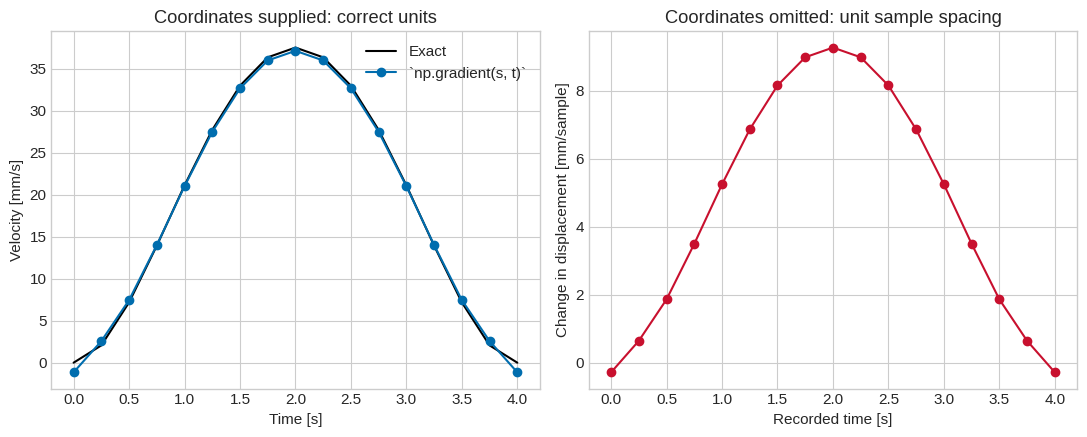

In [ ]:
velocity_coordinates = np.gradient(s, t, edge_order=2)
velocity_unit_spacing = np.gradient(s, edge_order=2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(t, 1e3*velocity_exact, color="black", label="Exact")
axes[0].plot(t, 1e3*velocity_coordinates, "o-", color=BLUE, label="`np.gradient(s, t)`")
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Velocity [mm/s]")
axes[0].set_title("Coordinates supplied: correct units")
axes[0].legend()

axes[1].plot(t, 1e3*velocity_unit_spacing, "o-", color=RED)
axes[1].set_xlabel("Recorded time [s]")
axes[1].set_ylabel("Change in displacement [mm/sample]")
axes[1].set_title("Coordinates omitted: unit sample spacing")
fig.tight_layout()
plt.show()


### ⚠️ Coordinate contract

`np.gradient(s)` differentiates with respect to **sample index**, not time. It cannot be
relabelled as velocity in m/s. This is the differentiation version of the Week 6 warning
about integrating against an index instead of the physical coordinate.


## 📂 7.1.7 Second derivatives

Adding the Taylor expansions on either side of $x_i$ eliminates the odd derivative
terms and gives the centred second difference

$$
f''(x_i)\approx\frac{f_{i+1}-2f_i+f_{i-1}}{h^2}+O(h^2).
$$

For actuator position, this estimates acceleration. Its units are

$$
\frac{\text{displacement [m]}}{(\text{time [s]})^2}=\text{acceleration [m/s}^2\text{]}.
$$

Calling `np.gradient` twice is convenient, but the second operation also differentiates
the errors created by the first.


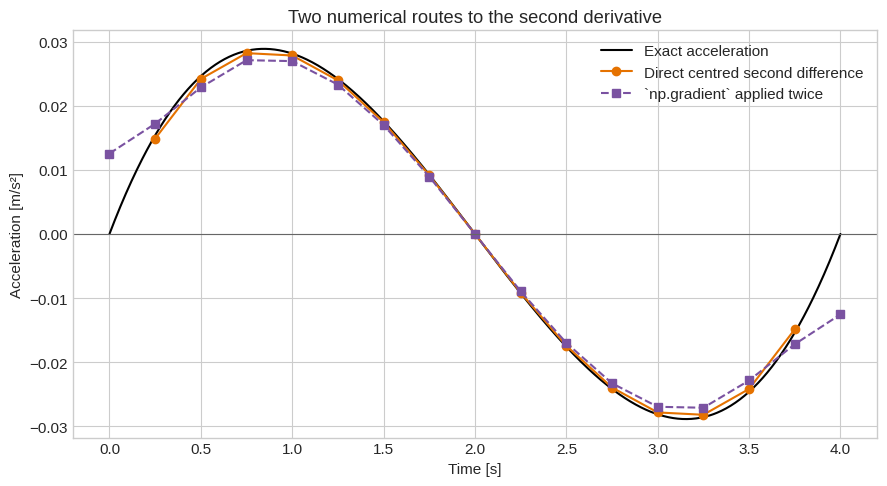

In [ ]:
acceleration_direct = np.empty_like(s)
acceleration_direct[:] = np.nan
acceleration_direct[1:-1] = (s[2:] - 2*s[1:-1] + s[:-2]) / h**2
acceleration_twice = np.gradient(np.gradient(s, t, edge_order=2), t, edge_order=2)

plt.figure(figsize=(9, 5))
plt.plot(time_dense, acceleration_model(time_dense), color="black",
         label="Exact acceleration")
plt.plot(t[1:-1], acceleration_direct[1:-1], "o-", color=ORANGE,
         label="Direct centred second difference")
plt.plot(t, acceleration_twice, "s--", color=PURPLE,
         label="`np.gradient` applied twice")
plt.axhline(0, color="0.4", linewidth=0.8)
plt.xlabel("Time [s]")
plt.ylabel("Acceleration [m/s²]")
plt.title("Two numerical routes to the second derivative")
plt.legend()
plt.tight_layout()
plt.show()


The direct three-point formula is defined only at interior samples in this example.
NumPy supplies boundary estimates, but those boundary values use different effective
stencils and should be interpreted separately from the interior.


## 📂 7.1.8 Step-size convergence and observed order

Suppose an error behaves approximately as

$$
E(h)\approx C h^p,
$$

where $E(h)$ is an error measure, $C$ is a problem-dependent constant and $p$ is the
method's order. Comparing two step sizes gives an observed order

$$
p_{\mathrm{obs}}=
\frac{\log(E(h_2)/E(h_1))}{\log(h_2/h_1)}.
$$

This formula is meaningful only when the calculations are in the asymptotic truncation-
error regime. Noise, round-off or an insufficiently smooth function can hide the expected
slope.


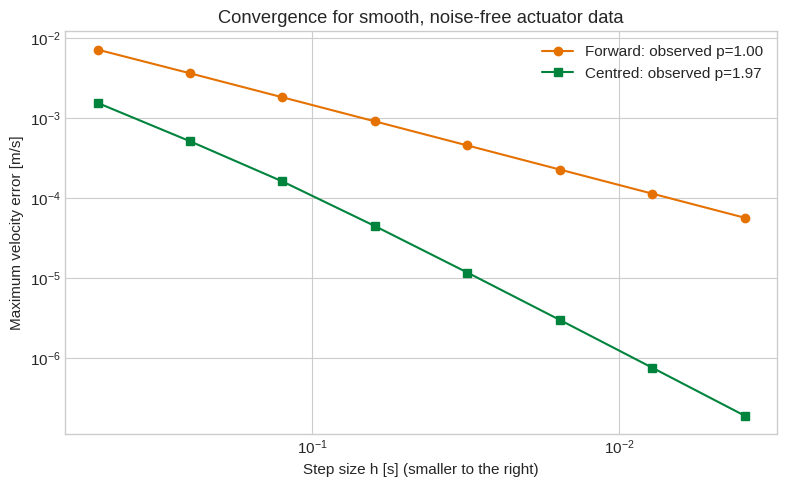

In [ ]:
sample_counts = 2**np.arange(3, 11) + 1
step_sizes = []
forward_errors = []
centred_errors = []

for n in sample_counts:
    t_n = np.linspace(0.0, MOVE_TIME_S, n)
    s_n = position_model(t_n)
    h_n = t_n[1] - t_n[0]
    fwd = (s_n[1:] - s_n[:-1]) / h_n
    ctr = (s_n[2:] - s_n[:-2]) / (2*h_n)
    step_sizes.append(h_n)
    forward_errors.append(np.max(np.abs(fwd - velocity_model(t_n[:-1]))))
    centred_errors.append(np.max(np.abs(ctr - velocity_model(t_n[1:-1]))))

step_sizes = np.array(step_sizes)
forward_errors = np.array(forward_errors)
centred_errors = np.array(centred_errors)
# Estimate the asymptotic slope using the five finest grids.
fit_slice = slice(-5, None)
p_forward = np.polyfit(
    np.log(step_sizes[fit_slice]), np.log(forward_errors[fit_slice]), 1
)[0]
p_centred = np.polyfit(
    np.log(step_sizes[fit_slice]), np.log(centred_errors[fit_slice]), 1
)[0]

plt.figure(figsize=(8, 5))
plt.loglog(step_sizes, forward_errors, "o-", color=ORANGE,
           label=f"Forward: observed p={p_forward:.2f}")
plt.loglog(step_sizes, centred_errors, "s-", color=GREEN,
           label=f"Centred: observed p={p_centred:.2f}")
plt.gca().invert_xaxis()
plt.xlabel("Step size h [s] (smaller to the right)")
plt.ylabel("Maximum velocity error [m/s]")
plt.title("Convergence for smooth, noise-free actuator data")
plt.legend()
plt.tight_layout()
plt.show()


### 🧠 Interpretation

For this smooth model, the forward estimate approaches first-order behaviour and the
centred estimate approaches second-order behaviour. Halving $h$ should therefore reduce
forward-difference truncation error by about $2$, and centred-difference truncation error
by about $2^2=4$.

This is evidence about the implemented method and this test problem. It is not proof that
an experimental derivative is accurate, because the exact derivative of an experiment is
usually unavailable.


## 📂 7.1.9 Why an extremely small step can fail

The centred numerator $f(x+h)-f(x-h)$ subtracts nearly equal floating-point values when
$h$ is extremely small. Significant digits can be lost before division by $2h$ magnifies
the remaining error. Total numerical error then reflects a competition:

* truncation error generally decreases as $h$ decreases; and
* round-off and cancellation error eventually increase as $h$ decreases.

The following calculation differentiates a known mathematical function, not measured
data, to isolate this floating-point effect.


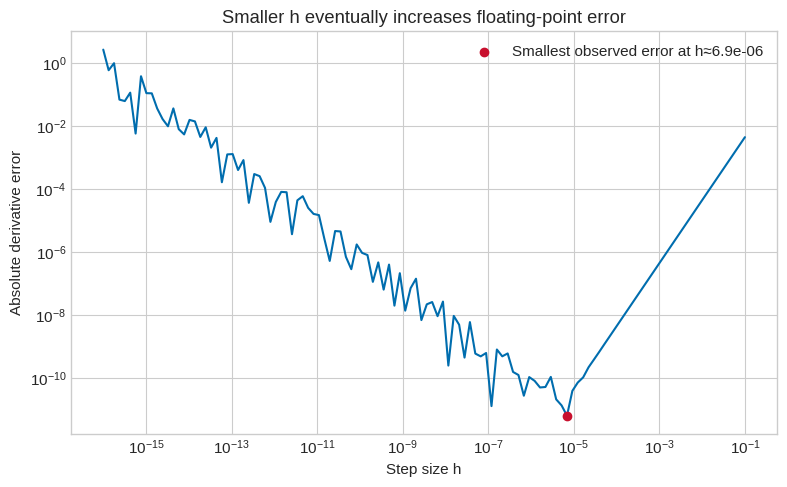

In [ ]:
x0 = 1.0
h_values = np.logspace(-16, -1, 120)
estimates = (np.exp(x0 + h_values) - np.exp(x0 - h_values)) / (2*h_values)
roundoff_errors = np.abs(estimates - np.exp(x0))
best_index = np.argmin(roundoff_errors)

plt.figure(figsize=(8, 5))
plt.loglog(h_values, roundoff_errors, color=BLUE)
plt.scatter(h_values[best_index], roundoff_errors[best_index], color=RED, zorder=4,
            label=f"Smallest observed error at h≈{h_values[best_index]:.1e}")
plt.xlabel("Step size h")
plt.ylabel("Absolute derivative error")
plt.title("Smaller h eventually increases floating-point error")
plt.legend()
plt.tight_layout()
plt.show()


### Key message

There is no universally optimal $h$. Its useful scale depends on the function, units,
numerical precision and—often more importantly in engineering—the measurement noise and
sensor resolution.


## 📂 7.1.10 Non-uniform sample coordinates

Real data may contain timing jitter, dropped samples or deliberately irregular sensor
locations. There is then no single constant $h$. For adjacent samples define

$$
h_i=t_{i+1}-t_i.
$$

`np.gradient(values, coordinates)` calculates weights using the actual neighbouring
coordinates. Using the mean spacing in a uniform-grid formula discards known information.


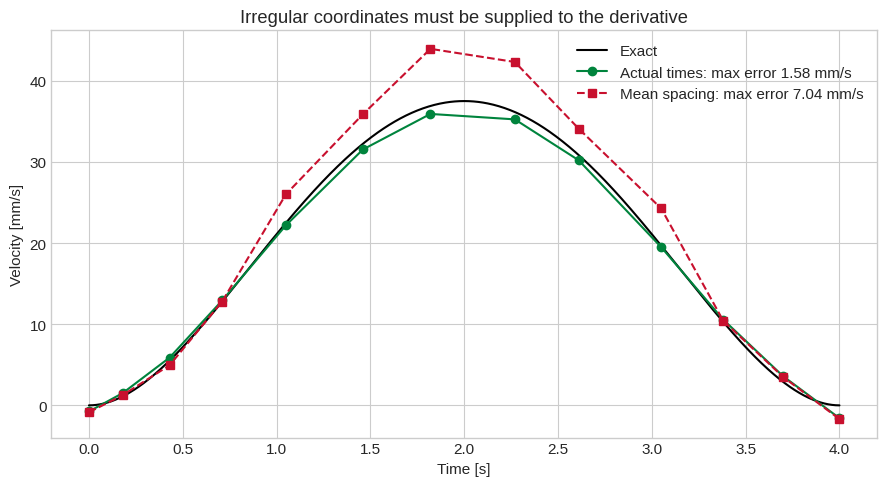

In [ ]:
time_irregular = np.array([0.00, 0.18, 0.43, 0.71, 1.05, 1.46, 1.82,
                           2.27, 2.61, 3.05, 3.38, 3.70, 4.00])
position_irregular = position_model(time_irregular)
mean_h = np.mean(np.diff(time_irregular))

velocity_actual_coordinates = np.gradient(
    position_irregular, time_irregular, edge_order=2
)
velocity_false_uniform = np.gradient(
    position_irregular, mean_h, edge_order=2
)
exact_irregular = velocity_model(time_irregular)

err_actual = np.max(np.abs(velocity_actual_coordinates - exact_irregular))
err_false = np.max(np.abs(velocity_false_uniform - exact_irregular))

plt.figure(figsize=(9, 5))
plt.plot(time_dense, 1e3*velocity_model(time_dense), color="black", label="Exact")
plt.plot(time_irregular, 1e3*velocity_actual_coordinates, "o-", color=GREEN,
         label=f"Actual times: max error {1e3*err_actual:.2f} mm/s")
plt.plot(time_irregular, 1e3*velocity_false_uniform, "s--", color=RED,
         label=f"Mean spacing: max error {1e3*err_false:.2f} mm/s")
plt.xlabel("Time [s]")
plt.ylabel("Velocity [mm/s]")
plt.title("Irregular coordinates must be supplied to the derivative")
plt.legend()
plt.tight_layout()
plt.show()


### ⚠️ Engineering warning

Always inspect that coordinates are finite, strictly ordered and expressed in the
intended units before differentiating. Duplicate time stamps make a local denominator
zero. Sorting coordinates without applying the same reordering to the measured values
destroys the sample pairs.


## 📂 7.1.11 Differentiation amplifies measurement noise

Let a measured displacement be

$$
s_i^{\mathrm{meas}}=s(t_i)+\varepsilon_i,
$$

where $\varepsilon_i$ is measurement error. A centred velocity estimate contains

$$
\frac{\varepsilon_{i+1}-\varepsilon_{i-1}}{2h}.
$$

Dividing by $h$ can make small sample-to-sample errors dominate the derivative. A second
derivative divides a second difference by $h^2$ and is typically even more sensitive.


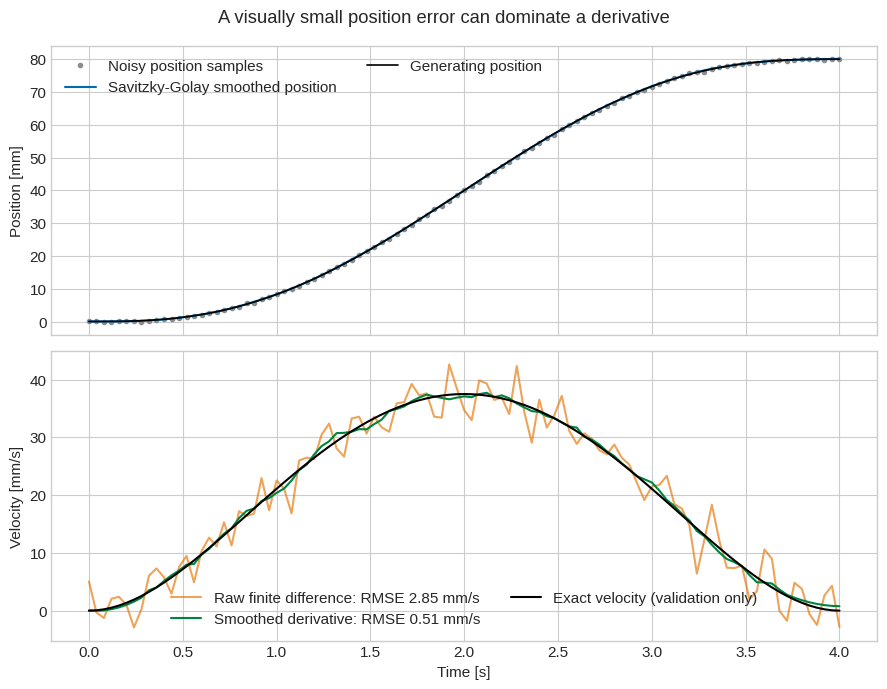

In [ ]:
rng = np.random.default_rng(71)
time_sensor = np.linspace(0.0, MOVE_TIME_S, 101)
dt_sensor = time_sensor[1] - time_sensor[0]
position_true = position_model(time_sensor)
noise_std_m = 0.00020  # 0.20 mm position noise
position_measured = position_true + rng.normal(0.0, noise_std_m, time_sensor.size)

velocity_raw = np.gradient(position_measured, time_sensor, edge_order=2)
position_smoothed = savgol_filter(position_measured, window_length=15, polyorder=3)
velocity_smoothed = savgol_filter(
    position_measured, window_length=15, polyorder=3,
    deriv=1, delta=dt_sensor
)
velocity_true = velocity_model(time_sensor)

rmse_raw = np.sqrt(np.mean((velocity_raw - velocity_true)**2))
rmse_smoothed = np.sqrt(np.mean((velocity_smoothed - velocity_true)**2))

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(time_sensor, 1e3*position_measured, ".", color="0.55",
             label="Noisy position samples")
axes[0].plot(time_sensor, 1e3*position_smoothed, color=BLUE,
             label="Savitzky-Golay smoothed position")
axes[0].plot(time_sensor, 1e3*position_true, color="black", linewidth=1.2,
             label="Generating position")
axes[0].set_ylabel("Position [mm]")
axes[0].legend(ncols=2)

axes[1].plot(time_sensor, 1e3*velocity_raw, color=ORANGE, alpha=0.65,
             label=f"Raw finite difference: RMSE {1e3*rmse_raw:.2f} mm/s")
axes[1].plot(time_sensor, 1e3*velocity_smoothed, color=GREEN,
             label=f"Smoothed derivative: RMSE {1e3*rmse_smoothed:.2f} mm/s")
axes[1].plot(time_sensor, 1e3*velocity_true, color="black", linewidth=1.5,
             label="Exact velocity (validation only)")
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Velocity [mm/s]")
axes[1].legend(ncols=2)
fig.suptitle("A visually small position error can dominate a derivative")
fig.tight_layout()
plt.show()


### ⚠️ Smoothing is a modelling decision

The Savitzky-Golay result is not a new measurement. It assumes that a low-degree
polynomial represents the signal within each moving window. A wider window usually
suppresses more noise but may flatten a real transient or shift the apparent peak.

A defensible report states the window length, polynomial order, sample interval and
boundary treatment, then checks whether conclusions persist across reasonable settings.
Never select smoothing parameters solely because the resulting curve looks attractive.


## 📂 7.1.12 Partial derivatives on a two-dimensional grid

A scalar temperature field $T(x,y)$ has one spatial derivative for each coordinate:

$$
\nabla T =
\begin{bmatrix}
\partial T/\partial x\\[2pt]
\partial T/\partial y
\end{bmatrix}.
$$

The gradient points in the direction of fastest temperature increase. In conduction,
Fourier's law uses the opposite direction: $\mathbf{q}=-k\nabla T$, where $\mathbf{q}$
is heat flux [W/m²] and $k$ is thermal conductivity [W/(m·K)].

The following plate field is synthetic. Its purpose is to practise coordinate and array-
axis handling before later PDE content.


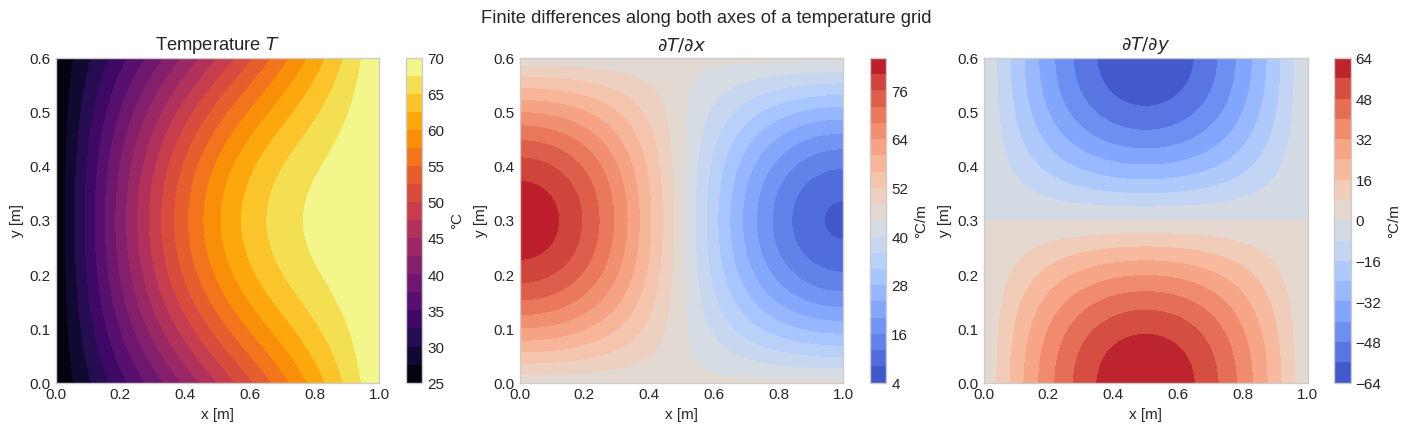

In [ ]:
x_plate = np.linspace(0.0, 1.0, 61)
y_plate = np.linspace(0.0, 0.6, 41)
X, Y = np.meshgrid(x_plate, y_plate)
temperature = 25 + 45*X + 12*np.sin(np.pi*X)*np.sin(np.pi*Y/0.6)

# Axis 0 follows y (rows); axis 1 follows x (columns).
dT_dy, dT_dx = np.gradient(
    temperature, y_plate, x_plate, edge_order=2
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)
fields = [temperature, dT_dx, dT_dy]
titles = ["Temperature $T$", "$\\partial T/\\partial x$", "$\\partial T/\\partial y$"]
units = ["°C", "°C/m", "°C/m"]
cmaps = ["inferno", "coolwarm", "coolwarm"]
for ax, field, title, unit, cmap in zip(axes, fields, titles, units, cmaps):
    image = ax.contourf(X, Y, field, levels=18, cmap=cmap)
    fig.colorbar(image, ax=ax, label=unit)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title(title)
fig.suptitle("Finite differences along both axes of a temperature grid")
plt.show()


### ⚠️ Array-axis warning

With `X, Y = np.meshgrid(x, y)`, rows vary in $y$ and columns vary in $x$. Therefore
`np.gradient(T, y, x)` returns the $y$ derivative first and the $x$ derivative second.
Check array shapes and coordinate ordering rather than guessing from variable names.


## 📂 7.1.13 Optional interactive sampling and noise demonstration

Use the controls to vary sample count and position-noise standard deviation. The same
random seed is reused so the comparison isolates the selected settings. Observe that
increasing the sample count decreases $h$ but can magnify the derivative of fixed-
amplitude measurement noise.


In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    def derivative_explorer(sample_count=41, noise_mm=0.10):
        t_w = np.linspace(0.0, MOVE_TIME_S, sample_count)
        rng_w = np.random.default_rng(710)
        measured_w = position_model(t_w) + rng_w.normal(
            0.0, noise_mm/1000, sample_count
        )
        velocity_w = np.gradient(measured_w, t_w, edge_order=2)

        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        axes[0].plot(t_w, 1e3*measured_w, "o-", ms=3, color=BLUE,
                     label="Measured position")
        axes[0].plot(time_dense, 1e3*position_model(time_dense), color="black",
                     linewidth=1, label="Generating model")
        axes[0].set_xlabel("Time [s]")
        axes[0].set_ylabel("Position [mm]")
        axes[0].legend()

        axes[1].plot(t_w, 1e3*velocity_w, "o-", ms=3, color=ORANGE,
                     label="Finite-difference velocity")
        axes[1].plot(time_dense, 1e3*velocity_model(time_dense), color="black",
                     linewidth=1, label="Exact derivative")
        axes[1].set_xlabel("Time [s]")
        axes[1].set_ylabel("Velocity [mm/s]")
        axes[1].legend()
        fig.suptitle(f"h={t_w[1]-t_w[0]:.3f} s, noise σ={noise_mm:.2f} mm")
        fig.tight_layout()
        plt.show()

    controls = {
        "sample_count": widgets.IntSlider(
            value=41, min=11, max=101, step=10, description="Samples"
        ),
        "noise_mm": widgets.FloatSlider(
            value=0.10, min=0.0, max=0.50, step=0.05,
            description="Noise σ [mm]", readout_format=".2f"
        ),
    }
    output = widgets.interactive_output(derivative_explorer, controls)
    display(widgets.VBox([widgets.HBox(list(controls.values())), output]))
except ImportError:
    print("ipywidgets is unavailable; all static demonstrations above remain complete.")


## 📂 7.1.14 Choosing a differentiation strategy

| Situation | Defensible starting point | Required checks |
|---|---|---|
| Smooth function, interior point | Centred difference | Step-size convergence and units |
| First or last sample | One-sided stencil | Boundary order and stencil width |
| Irregular coordinates | `np.gradient(values, coordinates)` | Ordering, duplicates and local spacing |
| Streaming estimate using only past data | Backward difference | Delay, sampling rate and noise |
| Noisy experimental record | Filtering or local fitting, then differentiation | Sensitivity to smoothing choices |
| Second derivative | Direct second difference or differentiated fit | Stronger noise amplification and boundaries |
| Multi-dimensional grid | Gradient along named coordinate axes | Axis order, spacing and physical units |

The method is not selected by accuracy order alone. Availability of neighbouring data,
sensor quality, latency, boundaries and the intended engineering decision all matter.


## 📂 7.1.15 Useful packages and functions

| Tool | Purpose | Important arguments |
|---|---|---|
| `np.diff(values)` | Adjacent discrete differences | Reduces the selected axis length by one |
| `np.gradient(values, coordinates)` | First derivative with boundary estimates | Supply physical coordinates; consider `edge_order=2` |
| `savgol_filter(...)` | Local polynomial smoothing or derivatives | `window_length`, `polyorder`, `deriv`, `delta` |
| `scipy.differentiate.derivative` | Adaptive derivative of a callable function | Availability depends on SciPy version; inspect convergence status |
| `plt.loglog(...)` | Display power-law convergence | Label the error norm and step-size definition |

`np.gradient` is the main tool for sampled arrays in this notebook. SciPy's
`differentiate` module addresses callable mathematical models and is not a substitute
for handling sensor noise in an experimental record.


## 📂 7.1.16 A reusable engineering workflow

1. Define the independent coordinate and its units.
2. Plot the sampled quantity before differentiating.
3. Check shape, ordering, duplicate coordinates and spacing.
4. Choose a stencil compatible with boundaries and data availability.
5. Calculate the derivative using the actual coordinates.
6. Verify the implementation on a known smooth function when possible.
7. Study step size, boundary behaviour and noise sensitivity.
8. Report assumptions, units, smoothing and limitations with the result.

The helper below implements these checks for a one-dimensional sampled record. It does
not decide whether smoothing is justified; that remains an engineering judgement.


In [ ]:
def differentiate_record(coordinates, values, *, edge_order=2):
    '''Validate and differentiate one sampled one-dimensional record.'''
    coordinates = np.asarray(coordinates, dtype=float)
    values = np.asarray(values, dtype=float)
    if coordinates.ndim != 1 or values.ndim != 1:
        raise ValueError("coordinates and values must both be one-dimensional")
    if coordinates.shape != values.shape:
        raise ValueError("coordinates and values must have the same shape")
    if coordinates.size < edge_order + 1:
        raise ValueError("not enough samples for the selected boundary order")
    if not np.all(np.isfinite(coordinates)) or not np.all(np.isfinite(values)):
        raise ValueError("coordinates and values must be finite")
    if not np.all(np.diff(coordinates) > 0):
        raise ValueError("coordinates must be strictly increasing")
    return np.gradient(values, coordinates, edge_order=edge_order)

checked_velocity = differentiate_record(time_irregular, position_irregular)
print("Validated irregular record")
print(f"Samples: {time_irregular.size}")
print(f"Spacing range: {np.diff(time_irregular).min():.3f} to "
      f"{np.diff(time_irregular).max():.3f} s")
print(f"Peak estimated velocity: {1e3*np.max(checked_velocity):.3f} mm/s")


Validated irregular record
Samples: 13
Spacing range: 0.180 to 0.450 s
Peak estimated velocity: 35.914 mm/s


## 📂 7.1.17 Summary

### Key definitions

* A finite difference estimates a derivative from a weighted combination of nearby
  sampled values.
* A stencil specifies which samples contribute to an estimate.
* The step size $h$ is a physical coordinate separation, not automatically one sample.
* Boundaries require one-sided information or a separately justified treatment.

### Method review

* Forward and backward two-point differences have leading truncation error $O(h)$.
* The centred first difference and centred second difference have leading error
  $O(h^2)$ for sufficiently smooth functions on uniform grids.
* `np.gradient(values, coordinates, edge_order=2)` is a useful default for complete
  sampled records, including irregular coordinates.
* Convergence studies test discretisation behaviour; they do not remove measurement
  uncertainty.
* Differentiation amplifies high-frequency error, so smoothing must be justified and
  reported rather than hidden.

### Engineering judgement

A credible derivative includes the coordinate and units, the stencil or package call,
boundary treatment, evidence of resolution sensitivity, and a discussion of noise.


## 🔗 Bridge to Notebook 7.2

This notebook began with sampled states and estimated their derivatives. An **ordinary
differential equation (ODE)** reverses the question: it specifies a relationship
involving a state derivative and asks how the state evolves.

Notebook 7.2 will define ODEs, state variables, initial conditions and initial-value
problems. Notebook 7.3 will then use derivative information to advance a state with
Euler's method.


## 📚 References

1. NumPy Developers, [`numpy.gradient`](https://numpy.org/doc/stable/reference/generated/numpy.gradient.html), accessed 2026.
2. SciPy Developers, [Finite Difference Differentiation](https://docs.scipy.org/doc/scipy/reference/differentiate.html), accessed 2026.
3. SciPy Developers, [`scipy.signal.savgol_filter`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.savgol_filter.html), accessed 2026.
4. B. Fornberg, “Generation of Finite Difference Formulas on Arbitrarily Spaced Grids,”
   *Mathematics of Computation*, 51(184), 699–706, 1988,
   [doi:10.1090/S0025-5718-1988-0935077-0](https://doi.org/10.1090/S0025-5718-1988-0935077-0).
